# Similarité cosinus des représentations

Cette analyse est descriptive : elle ne mesure pas une performance de généralisation. Les représentations sont moyennées sur toutes les dimensions sauf le batch et la dernière, puis normalisées sans centrage. Les comparaisons sont faites uniquement entre essais d'un même sujet afin de ne pas confondre classe et identité du sujet. Chaque sujet contribue au même nombre maximal de paires, avec autant de paires de même classe que de classes différentes. L'incertitude est calculée sur les sujets, qui constituent l'unité statistique.

In [6]:
import gc
import warnings
from importlib import import_module
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="Importing from timm.models.layers is deprecated")
warnings.filterwarnings("ignore", message="Importing from timm.models.registry is deprecated")
warnings.filterwarnings("ignore", message="enable_nested_tensor is True")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import yaml
from torch.utils.data import DataLoader, Subset

from eeg_preprocessing.loaders import CustomDataset, get_subject_ids

ROOT = Path.cwd()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

WRAPPERS = {
    "cbramod": ("utils.wrappers.cbramod", "CBraModWrapper"),
    "csbrain": ("utils.wrappers.csbrain", "CSBrainWrapper"),
    "eegmamba": ("utils.wrappers.eegmamba", "EEGMambaWrapper"),
    "eegpt": ("utils.wrappers.eegpt", "EEGPTWrapper"),
    "labram": ("utils.wrappers.labram", "LaBraMWrapper"),
    "reve": ("utils.wrappers.reve", "ReveWrapper"),
    "lumamba": ("utils.wrappers.lumamba", "LuMambaWrapper"),
    "luna": ("utils.wrappers.luna", "LUNAWrapper"),
    "eegfm": ("utils.wrappers.eegfm", "EEGFMWrapper"),
    "eegnet": ("utils.wrappers.eegnet", "EEGNetWrapper"),
}

LMDB_PATHS = {
    "BCI2A": "/projects/EEG-foundation-model/RECH202/data_preprocessed_normalized/BCI2A/bci2a.lmdb",
    "FACED": "/projects/EEG-foundation-model/RECH202/data_preprocessed_normalized/FACED/faced.lmdb",
    "PHYSIONETMI": "/projects/EEG-foundation-model/RECH202/data_preprocessed_normalized/PHYSIONETMI/physionetmi.lmdb",
}

MODELS = ["reve"]
DATASETS = list(LMDB_PATHS)
CHANNEL_MODE = "mapped"
BATCH_SIZE = 64
NUM_WORKERS = 0
MAX_EPOCHS_TOTAL = 3000
MAX_PAIRS_PER_CONDITION = 50000
SEED = 100

In [7]:
class FeatureModel(nn.Module):
    def __init__(self, wrapper):
        super().__init__()
        self.wrapper = wrapper
        self.backbone = wrapper.backbone
        if hasattr(wrapper, "chan_conv"):
            self.chan_conv = wrapper.chan_conv

    def forward(self, x):
        return self.wrapper.forward_features(x)


def load_model_config(model_name):
    with open(ROOT / "utils" / "configs" / f"{model_name}.yaml") as f:
        return yaml.safe_load(f)


def get_wrapper_class(model_name):
    module_name, class_name = WRAPPERS[model_name]
    return getattr(import_module(module_name), class_name)


def load_feature_model(model_name, dataset, device=DEVICE):
    cfg = load_model_config(model_name)
    lmdb_path = LMDB_PATHS[dataset]
    sid = get_subject_ids(Path(lmdb_path))[0]
    x_sample, _ = CustomDataset(lmdb_path, subject_ids=[sid], channel_mode=CHANNEL_MODE)[0]
    n_channels, time_length = x_sample.shape

    ckpt_path = None
    if cfg.get("use_pretrained_weights", False):
        candidate = ROOT / cfg["pretrained_weights"]
        if not candidate.is_file():
            raise FileNotFoundError(f"Checkpoint introuvable: {candidate}")
        ckpt_path = str(candidate)

    wrapper_class = get_wrapper_class(model_name)
    wrapper = wrapper_class(ckpt_path=ckpt_path, dropout=cfg.get("dropout", 0.0))
    wrapper.build_backbone(n_channels=n_channels, time_length=time_length)
    wrapper.freeze_backbone()
    return FeatureModel(wrapper).to(device).eval()

In [8]:
def pool_features(z):
    if not isinstance(z, torch.Tensor):
        raise TypeError(f"Le backbone doit renvoyer un tenseur, reçu: {type(z).__name__}")
    if z.ndim < 2:
        raise ValueError(f"Forme de représentation invalide: {tuple(z.shape)}")
    dimensions = tuple(range(1, z.ndim - 1))
    return z.mean(dim=dimensions) if dimensions else z


def sampled_subject_dataset(lmdb_path, sid, limit, seed):
    dataset = CustomDataset(lmdb_path, subject_ids=[sid], channel_mode=CHANNEL_MODE)
    if limit is None or len(dataset) <= limit:
        return dataset
    rng = np.random.default_rng(seed)
    indices = np.sort(rng.choice(len(dataset), size=limit, replace=False))
    return Subset(dataset, indices.tolist())


@torch.inference_mode()
def extract_features(dataset, model, device=DEVICE, seed=SEED):
    lmdb_path = LMDB_PATHS[dataset]
    subject_ids = get_subject_ids(Path(lmdb_path))
    per_subject = None
    if MAX_EPOCHS_TOTAL is not None:
        per_subject = max(2, MAX_EPOCHS_TOTAL // len(subject_ids))

    features, labels, subjects = [], [], []
    for subject_index, sid in enumerate(subject_ids):
        ds = sampled_subject_dataset(lmdb_path, sid, per_subject, seed + subject_index)
        loader = DataLoader(
            ds,
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=device.type == "cuda",
        )
        for x, y in loader:
            x = model.wrapper.preprocess(x)
            x = x.to(device, dtype=torch.float32, non_blocking=True)
            pooled = pool_features(model(x))
            features.append(pooled.float().cpu().numpy())
            y = y.reshape(-1).cpu().numpy()
            labels.append(y)
            subjects.append(np.full(y.size, sid))
        print(f"{dataset}: sujet {subject_index + 1}/{len(subject_ids)}", end="\r")
    print()
    return np.concatenate(features), np.concatenate(labels), np.concatenate(subjects)

In [9]:
def within_subject_cosine(features, labels, subjects, max_pairs, seed=SEED):
    features = np.asarray(features, dtype=np.float32)
    norms = np.linalg.norm(features, axis=1, keepdims=True)
    features = features / np.maximum(norms, np.finfo(np.float32).eps)

    unique_subjects = np.unique(subjects)
    quota = max(1, max_pairs // len(unique_subjects))
    rng = np.random.default_rng(seed)
    same_samples, different_samples, rows = [], [], []

    for sid in unique_subjects:
        idx = np.flatnonzero(subjects == sid)
        if idx.size < 2:
            continue
        left, right = np.triu_indices(idx.size, k=1)
        similarities = np.einsum("ij,ij->i", features[idx[left]], features[idx[right]])
        is_same = labels[idx[left]] == labels[idx[right]]
        same = similarities[is_same]
        different = similarities[~is_same]
        if same.size == 0 or different.size == 0:
            continue

        n = min(quota, same.size, different.size)
        same_samples.append(rng.choice(same, size=n, replace=False))
        different_samples.append(rng.choice(different, size=n, replace=False))
        rows.append({
            "subject": sid,
            "same_mean": float(same.mean()),
            "different_mean": float(different.mean()),
            "delta": float(same.mean() - different.mean()),
            "n_same_pairs": int(same.size),
            "n_different_pairs": int(different.size),
        })

    if not rows:
        raise ValueError("Aucun sujet ne contient à la fois des paires de même classe et de classes différentes")
    return np.concatenate(same_samples), np.concatenate(different_samples), pd.DataFrame(rows)


def bootstrap_mean_ci(values, seed=SEED, n_bootstrap=5000):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    indices = rng.integers(0, values.size, size=(n_bootstrap, values.size))
    means = values[indices].mean(axis=1)
    return tuple(np.percentile(means, [2.5, 97.5]))


def plot_distributions(ax, same, different, subject_stats, dataset):
    combined = np.concatenate([same, different])
    x_low, x_high = np.quantile(combined, [0.005, 0.995])
    span = x_high - x_low
    margin = max(0.05 * span, 1e-4)
    x_low = max(-1.0, x_low - margin)
    x_high = min(1.0, x_high + margin)
    bins = np.linspace(x_low, x_high, 51)

    ax.hist(same, bins=bins, density=True, histtype="step", linewidth=2, color="tab:blue", label=f"Same class: mean={same.mean():.4f}")
    ax.hist(different, bins=bins, density=True, histtype="step", linewidth=2, color="tab:orange", label=f"Different classes: mean={different.mean():.4f}")
    delta = subject_stats["delta"].mean()
    low, high = bootstrap_mean_ci(subject_stats["delta"].to_numpy())
    ax.set_title(f"{dataset}\nMean subject Δ = {delta:.4f} [{low:.4f}, {high:.4f}]")
    ax.set_xlabel("Cosine similarity")
    ax.set_ylabel("Density")
    ax.set_xlim(x_low, x_high)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

[REVE] loaded pretrained weights from /home/infres/yrothlin-24/EEG_Benchmark/models/checkpoints/reve-base
BCI2A: sujet 9/9
[REVE] loaded pretrained weights from /home/infres/yrothlin-24/EEG_Benchmark/models/checkpoints/reve-base
FACED: sujet 123/123
[REVE] loaded pretrained weights from /home/infres/yrothlin-24/EEG_Benchmark/models/checkpoints/reve-base
PHYSIONETMI: sujet 109/109


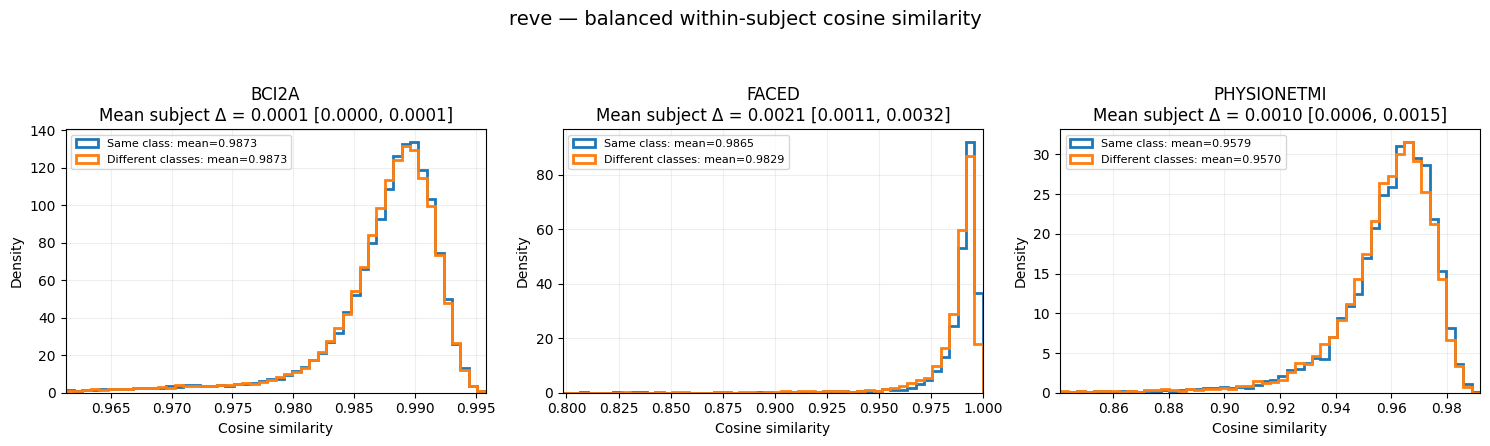

,model,dataset,n_epochs,n_subjects,same_cosine,different_cosine,subject_delta,ci_95_low,ci_95_high,positive_subjects
0,reve,BCI2A,2997,9,0.9873,0.9873,0.0001,0.0000,0.0001,0.8889
1,reve,FACED,2952,123,0.9865,0.9829,0.0021,0.0011,0.0032,0.8455
2,reve,PHYSIONETMI,2943,109,0.9579,0.9570,0.0010,0.0006,0.0015,0.6514


In [10]:
results = []

for model_name in MODELS:
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(5 * len(DATASETS), 4.5), squeeze=False)
    for ax, dataset in zip(axes[0], DATASETS):
        model = load_feature_model(model_name, dataset)
        features, labels, subjects = extract_features(dataset, model)
        same, different, subject_stats = within_subject_cosine(
            features, labels, subjects, MAX_PAIRS_PER_CONDITION, seed=SEED
        )
        plot_distributions(ax, same, different, subject_stats, dataset)

        low, high = bootstrap_mean_ci(subject_stats["delta"].to_numpy())
        results.append({
            "model": model_name,
            "dataset": dataset,
            "n_epochs": len(features),
            "n_subjects": len(subject_stats),
            "same_cosine": same.mean(),
            "different_cosine": different.mean(),
            "subject_delta": subject_stats["delta"].mean(),
            "ci_95_low": low,
            "ci_95_high": high,
            "positive_subjects": (subject_stats["delta"] > 0).mean(),
        })

        del model, features, labels, subjects, same, different, subject_stats
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    fig.suptitle(f"{model_name} — balanced within-subject cosine similarity", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()

results_df = pd.DataFrame(results)
display(results_df.round(4))